In [ ]:
import pandas as pd
import numpy as np

url = "https://raw.githubusercontent.com/ericm-006/product-category-classifier/main/IMLP6_TASK_03-products.csv"

df = pd.read_csv(url)

print("Dataset je uspešno učitan!")
print("Dimenzije dataset-a:", df.shape)

display(df.head())

Dataset je uspešno učitan!
Dimenzije dataset-a: (35311, 8)


,product ID,Product Title,Merchant ID,Category Label,_Product Code,Number_of_Views,Merchant Rating,Listing Date
0,1,apple iphone 8 plus 64gb silver,1,Mobile Phones,QA-2276-XC,860.0,2.5,5/10/2024
1,2,apple iphone 8 plus 64 gb spacegrau,2,Mobile Phones,KA-2501-QO,3772.0,4.8,12/31/2024
2,3,apple mq8n2b/a iphone 8 plus 64gb 5.5 12mp sim...,3,Mobile Phones,FP-8086-IE,3092.0,3.9,11/10/2024
3,4,apple iphone 8 plus 64gb space grey,4,Mobile Phones,YI-0086-US,466.0,3.4,5/2/2022
4,5,apple iphone 8 plus gold 5.5 64gb 4g unlocked ...,5,Mobile Phones,NZ-3586-WP,4426.0,1.6,4/12/2023


In [ ]:
# Osnovne informacije o dataset-u
print("INFORMACIJE O DATASET-U")
print("-" * 40)

df.info()

# Broj nedostajućih vrednosti
print("\nNEDOSTAJUĆE VREDNOSTI")
print("-" * 40)

print(df.isnull().sum())

# Broj različitih kategorija
print("\nBROJ RAZLIČITIH KATEGORIJA")
print("-" * 40)

print(df[" Category Label"].value_counts(dropna=False))

INFORMACIJE O DATASET-U
----------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35311 entries, 0 to 35310
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   product ID       35311 non-null  int64  
 1   Product Title    35139 non-null  object 
 2   Merchant ID      35311 non-null  int64  
 3    Category Label  35267 non-null  object 
 4   _Product Code    35216 non-null  object 
 5   Number_of_Views  35297 non-null  float64
 6   Merchant Rating  35141 non-null  float64
 7    Listing Date    35252 non-null  object 
dtypes: float64(2), int64(2), object(4)
memory usage: 2.2+ MB

NEDOSTAJUĆE VREDNOSTI
----------------------------------------
product ID           0
Product Title      172
Merchant ID          0
 Category Label     44
_Product Code       95
Number_of_Views     14
Merchant Rating    170
 Listing Date       59
dtype: int64

BROJ RAZLIČITIH KATEGORIJA
----------------

In [ ]:
# Pravljenje kopije originalnog dataset-a
df_clean = df.copy()

# Uklanjanje razmaka iz naziva kolona
df_clean.columns = df_clean.columns.str.strip()

# Uklanjanje redova bez naziva proizvoda ili kategorije
df_clean = df_clean.dropna(
    subset=["Product Title", "Category Label"]
)

# Uklanjanje praznih naziva proizvoda
df_clean["Product Title"] = df_clean["Product Title"].astype(str).str.strip()
df_clean = df_clean[df_clean["Product Title"] != ""]

# Ujednačavanje naziva kategorija
category_mapping = {
    "fridge": "Fridges",
    "CPU": "CPUs",
    "Mobile Phone": "Mobile Phones"
}

df_clean["Category Label"] = df_clean["Category Label"].replace(category_mapping)

# Prikaz rezultata
print("ČIŠĆENJE PODATAKA ZAVRŠENO")
print("-" * 40)

print("Broj redova pre čišćenja:", len(df))
print("Broj redova nakon čišćenja:", len(df_clean))
print("Broj uklonjenih redova:", len(df) - len(df_clean))

print("\nBroj kategorija:", df_clean["Category Label"].nunique())

print("\nRaspodela kategorija:")
print(df_clean["Category Label"].value_counts())

ČIŠĆENJE PODATAKA ZAVRŠENO
----------------------------------------
Broj redova pre čišćenja: 35311
Broj redova nakon čišćenja: 35096
Broj uklonjenih redova: 215

Broj kategorija: 10

Raspodela kategorija:
Category Label
Fridge Freezers     5470
Mobile Phones       4057
Washing Machines    4015
CPUs                3831
Fridges             3559
TVs                 3541
Dishwashers         3405
Digital Cameras     2689
Microwaves          2328
Freezers            2201
Name: count, dtype: int64


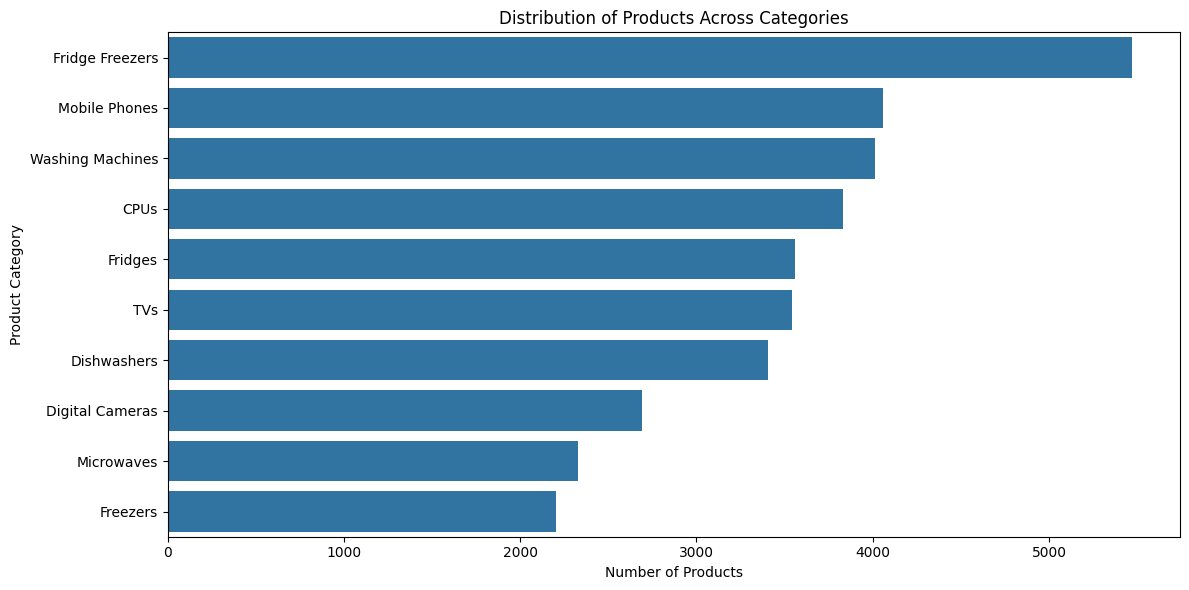

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Broj proizvoda po kategorijama
category_counts = df_clean["Category Label"].value_counts()

# Kreiranje grafikona
plt.figure(figsize=(12, 6))

sns.barplot(
    x=category_counts.values,
    y=category_counts.index
)

plt.title("Distribution of Products Across Categories")
plt.xlabel("Number of Products")
plt.ylabel("Product Category")

plt.tight_layout()
plt.show()

In [ ]:
# Provera naziva proizvoda
print("PRIMERI NAZIVA PROIZVODA")
print("-" * 50)

for title in df_clean["Product Title"].head(15):
    print(title)

# Provera praznih i dupliranih naziva
print("\nBROJ PRAZNIH NAZIVA:")
print(df_clean["Product Title"].isnull().sum())

print("\nBROJ DUPLIRANIH NAZIVA:")
print(df_clean["Product Title"].duplicated().sum())

# Prosečna dužina naziva proizvoda
df_clean["title_length"] = df_clean["Product Title"].str.len()

print("\nPROSEČNA DUŽINA NAZIVA:")
print(df_clean["title_length"].mean())

print("\nNAJKRAĆI NAZIV:")
print(df_clean["title_length"].min())

print("\nNAJDUŽI NAZIV:")
print(df_clean["title_length"].max())

PRIMERI NAZIVA PROIZVODA
--------------------------------------------------
apple iphone 8 plus 64gb silver
apple iphone 8 plus 64 gb spacegrau
apple mq8n2b/a iphone 8 plus 64gb 5.5 12mp sim free smartphone in gold
apple iphone 8 plus 64gb space grey
apple iphone 8 plus gold 5.5 64gb 4g unlocked sim free
apple iphone 8 plus gold 5.5 64gb 4g unlocked sim free
apple iphone 8 plus 64 gb space grey
apple iphone 8 plus 64gb space grey
apple iphone 8 plus 64gb space grey
apple iphone 8 plus 64gb space grey
apple iphone 8 plus 5.5 single sim 4g 64gb silver
sim free iphone 8 plus 64gb by apple space grey
apple iphone 8 plus 64gb gold smartphone
apple iphone 8 plus 5.5 single sim 4g 64gb grey
apple iphone 8 plus silver 5.5 64gb 4g unlocked sim free

BROJ PRAZNIH NAZIVA:
0

BROJ DUPLIRANIH NAZIVA:
4272

PROSEČNA DUŽINA NAZIVA:
52.98481308411215

NAJKRAĆI NAZIV:
5

NAJDUŽI NAZIV:
200


In [ ]:
import re

def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

df_clean["clean_title"] = df_clean["Product Title"].apply(clean_text)

# Prikaz originalnih i očišćenih naziva
print("ORIGINALNI I OČIŠĆENI NAZIVI")
print("-" * 60)

for original, cleaned in zip(
    df_clean["Product Title"].head(10),
    df_clean["clean_title"].head(10)
):
    print("Original:", original)
    print("Očišćen:", cleaned)
    print("-" * 60)

ORIGINALNI I OČIŠĆENI NAZIVI
------------------------------------------------------------
Original: apple iphone 8 plus 64gb silver
Očišćen: apple iphone 8 plus 64gb silver
------------------------------------------------------------
Original: apple iphone 8 plus 64 gb spacegrau
Očišćen: apple iphone 8 plus 64 gb spacegrau
------------------------------------------------------------
Original: apple mq8n2b/a iphone 8 plus 64gb 5.5 12mp sim free smartphone in gold
Očišćen: apple mq8n2b a iphone 8 plus 64gb 5 5 12mp sim free smartphone in gold
------------------------------------------------------------
Original: apple iphone 8 plus 64gb space grey
Očišćen: apple iphone 8 plus 64gb space grey
------------------------------------------------------------
Original: apple iphone 8 plus gold 5.5 64gb 4g unlocked sim free
Očišćen: apple iphone 8 plus gold 5 5 64gb 4g unlocked sim free
------------------------------------------------------------
Original: apple iphone 8 plus gold 5.5 64gb 4g unl

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Kreiranje TF-IDF vektorizatora
tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=20000,
    min_df=2,
    sublinear_tf=True
)

# Pretvaranje naziva proizvoda u numeričke karakteristike
X = tfidf.fit_transform(df_clean["clean_title"])

# Ciljna promenljiva - kategorije proizvoda
y = df_clean["Category Label"]

print("TF-IDF VEKTORIZACIJA ZAVRŠENA")
print("-" * 40)

print("Broj proizvoda:", X.shape[0])
print("Broj TF-IDF karakteristika:", X.shape[1])
print("Broj kategorija:", y.nunique())
print("Dimenzije matrice:", X.shape)

TF-IDF VEKTORIZACIJA ZAVRŠENA
----------------------------------------
Broj proizvoda: 35096
Broj TF-IDF karakteristika: 20000
Broj kategorija: 10
Dimenzije matrice: (35096, 20000)


In [ ]:
from sklearn.model_selection import train_test_split

# Podela podataka na trening i test skup
X_train, X_test, y_train, y_test = train_test_split(
    df_clean["clean_title"],
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("PODELA PODATAKA ZAVRŠENA")
print("-" * 40)

print("Trening skup:", len(X_train))
print("Test skup:", len(X_test))

print("\nBroj proizvoda po kategorijama u trening skupu:")
print(y_train.value_counts())

print("\nBroj proizvoda po kategorijama u test skupu:")
print(y_test.value_counts())

PODELA PODATAKA ZAVRŠENA
----------------------------------------
Trening skup: 28076
Test skup: 7020

Broj proizvoda po kategorijama u trening skupu:
Category Label
Fridge Freezers     4376
Mobile Phones       3245
Washing Machines    3212
CPUs                3065
Fridges             2847
TVs                 2833
Dishwashers         2724
Digital Cameras     2151
Microwaves          1862
Freezers            1761
Name: count, dtype: int64

Broj proizvoda po kategorijama u test skupu:
Category Label
Fridge Freezers     1094
Mobile Phones        812
Washing Machines     803
CPUs                 766
Fridges              712
TVs                  708
Dishwashers          681
Digital Cameras      538
Microwaves           466
Freezers             440
Name: count, dtype: int64


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB

# Definisanje modela
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1500,
        class_weight="balanced",
        C=4
    ),

    "Linear SVM": LinearSVC(
        class_weight="balanced"
    ),

    "Multinomial Naive Bayes": MultinomialNB(
        alpha=0.25
    )
}

trained_models = {}

# Treniranje svih modela
for name, model in models.items():

    print(f"\nTreniranje modela: {name}")

    pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(
            ngram_range=(1, 2),
            max_features=20000,
            min_df=2,
            sublinear_tf=True
        )),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

    print(f"{name} je uspešno treniran!")

print("\nSVI MODELI SU TRENIRANI!")


Treniranje modela: Logistic Regression
Logistic Regression je uspešno treniran!

Treniranje modela: Linear SVM
Linear SVM je uspešno treniran!

Treniranje modela: Multinomial Naive Bayes
Multinomial Naive Bayes je uspešno treniran!

SVI MODELI SU TRENIRANI!


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

results = []

for name, pipeline in trained_models.items():

    # Predviđanje kategorija
    y_pred = pipeline.predict(X_test)

    # Izračunavanje metrika
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred, average="weighted", zero_division=0
    )
    recall = recall_score(
        y_test, y_pred, average="weighted", zero_division=0
    )
    f1 = f1_score(
        y_test, y_pred, average="weighted", zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1
    })

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)
    print(classification_report(y_test, y_pred, zero_division=0))

# Tabela za poređenje modela
results_df = pd.DataFrame(results)

print("\nPOREĐENJE MODELA")
display(
    results_df.sort_values(
        by="F1-score",
        ascending=False
    ).reset_index(drop=True)
)


Logistic Regression
                  precision    recall  f1-score   support

            CPUs       1.00      0.99      1.00       766
 Digital Cameras       1.00      1.00      1.00       538
     Dishwashers       0.91      0.97      0.94       681
        Freezers       0.90      0.96      0.93       440
 Fridge Freezers       0.97      0.93      0.95      1094
         Fridges       0.91      0.91      0.91       712
      Microwaves       0.98      0.97      0.98       466
   Mobile Phones       0.97      0.99      0.98       812
             TVs       0.98      0.99      0.98       708
Washing Machines       0.98      0.93      0.96       803

        accuracy                           0.96      7020
       macro avg       0.96      0.96      0.96      7020
    weighted avg       0.96      0.96      0.96      7020


Linear SVM
                  precision    recall  f1-score   support

            CPUs       1.00      1.00      1.00       766
 Digital Cameras       1.00      1.

,Model,Accuracy,Precision,Recall,F1-score
0,Linear SVM,0.964245,0.964838,0.964245,0.964304
1,Multinomial Naive Bayes,0.961681,0.962431,0.961681,0.961617
2,Logistic Regression,0.960969,0.961795,0.960969,0.961054


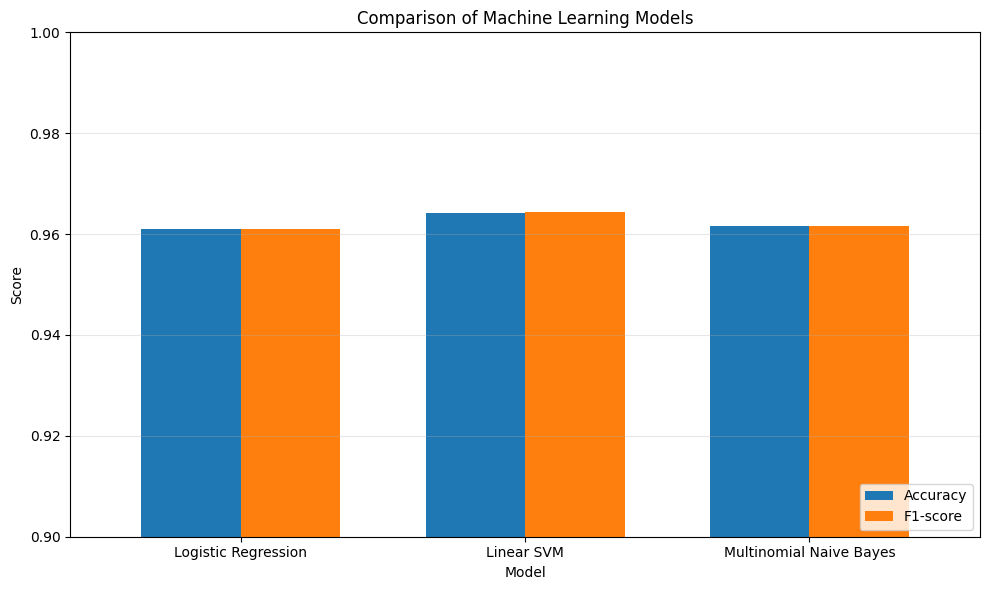

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

comparison = results_df.set_index("Model")

metrics = ["Accuracy", "F1-score"]

ax = comparison[metrics].plot(
    kind="bar",
    figsize=(10, 6),
    width=0.7
)

plt.title("Comparison of Machine Learning Models")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0.90, 1.00)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
import os
import joblib

# Kreiranje foldera za modele
os.makedirs("models", exist_ok=True)

# Izdvajanje najboljeg modela
best_model = trained_models["Linear SVM"]

# Čuvanje modela
joblib.dump(
    best_model,
    "models/product_category_model.pkl"
)

print("Model je uspešno sačuvan!")
print("Lokacija: models/product_category_model.pkl")

Model je uspešno sačuvan!
Lokacija: models/product_category_model.pkl


In [ ]:
# Učitavanje sačuvanog modela
loaded_model = joblib.load(
    "models/product_category_model.pkl"
)

# Testiranje modela
test_products = [
    "apple iphone 15 pro max 256gb",
    "samsung 55 inch 4k smart television",
    "intel core i9 processor",
    "bosch washing machine 8kg",
    "lg frost free fridge freezer"
]

predictions = loaded_model.predict(test_products)

for product, category in zip(test_products, predictions):
    print(f"Proizvod: {product}")
    print(f"Predviđena kategorija: {category}")
    print("-" * 50)

Proizvod: apple iphone 15 pro max 256gb
Predviđena kategorija: Mobile Phones
--------------------------------------------------
Proizvod: samsung 55 inch 4k smart television
Predviđena kategorija: TVs
--------------------------------------------------
Proizvod: intel core i9 processor
Predviđena kategorija: CPUs
--------------------------------------------------
Proizvod: bosch washing machine 8kg
Predviđena kategorija: Washing Machines
--------------------------------------------------
Proizvod: lg frost free fridge freezer
Predviđena kategorija: Fridge Freezers
--------------------------------------------------


In [ ]:
from google.colab import files

files.download("models/product_category_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>